# Análisis de series de tiempo

Notebook dedicado al análisis de series de tiempo de las licitaciones (obtenidas de ChileCompra) realizadas por el Estado chileno entre los años **2023 y 2025**. El objetivo es estudiar cómo ha evolucionado la cantidad de licitaciones durante este período, identificando tendencias, patrones estacionales y posibles comportamientos atípicos. Además, se busca evaluar distintos modelos de pronóstico para predecir el comportamiento de las licitaciones a corto plazo.

## Librerias

In [53]:
import warnings
warnings.filterwarnings("ignore")
warnings.filterwarnings("ignore", category=DeprecationWarning)
import logging
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)

# %pip install pmdarima

import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pmdarima as pm

from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True

## Carga y limpieza

El archivo `serie_tiempo_limpia.csv` contiene la cantidad semanal de licitaciones realizadas por el Estado chileno entre los años **2023 y 2025**, a partir de los datos obtenidos desde ChileCompra. Estos datos serán utilizados para realizar el análisis temporal y evaluar los modelos de pronóstico.

In [13]:
lic = pd.read_csv("serie_tiempo_limpia.csv")

import warnings
warnings.filterwarnings(
    "ignore",
    category=DeprecationWarning,
    module="jupyter_client"
)


# Convertir a semana (semana/semana -> semana[0])
lic["Semana"] = pd.to_datetime(
    lic["Semana"].str.split("/").str[0]
)
lic = lic.sort_values("Semana").reset_index(drop=True)
lic = lic.set_index("Semana")

# Agrupación total
lic_total = lic.groupby("Semana")["Volumen_Licitaciones"].sum()
lic_total = lic_total.asfreq("W-MON")

print("Cantidad de semanas:", len(lic_total))
print("Semanas faltantes:", lic_total.isnull().sum())
print(lic_total.describe())


Cantidad de semanas: 157
Semanas faltantes: 0
count     157.000000
mean     2544.012739
std       758.223869
min       442.000000
25%      1978.000000
50%      2660.000000
75%      3142.000000
max      4051.000000
Name: Volumen_Licitaciones, dtype: float64


## Resampling y exploración
Se construye la serie temporal semanal y mensual, se grafica la semanal junto a una media móvil de 4 semanas.

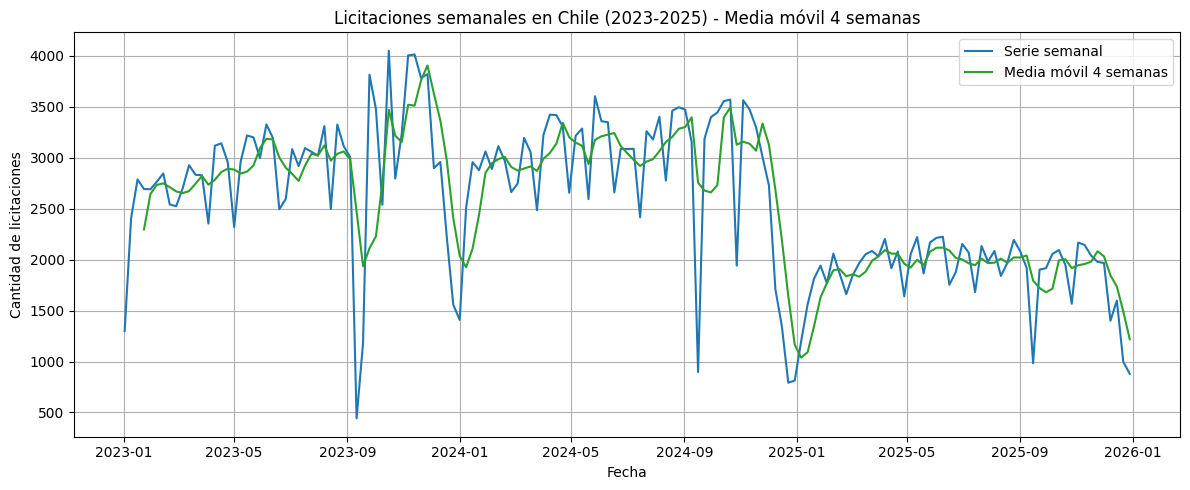

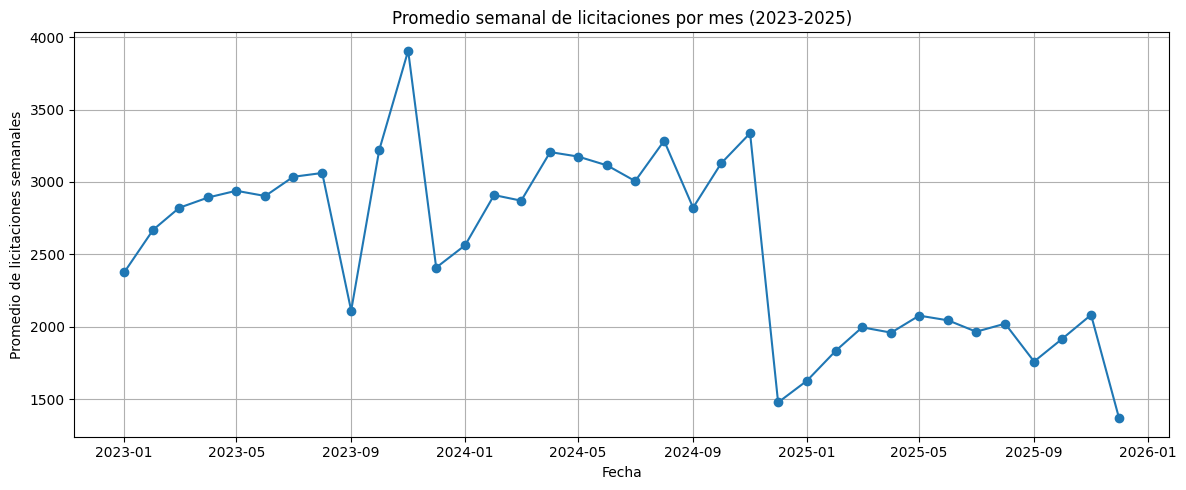

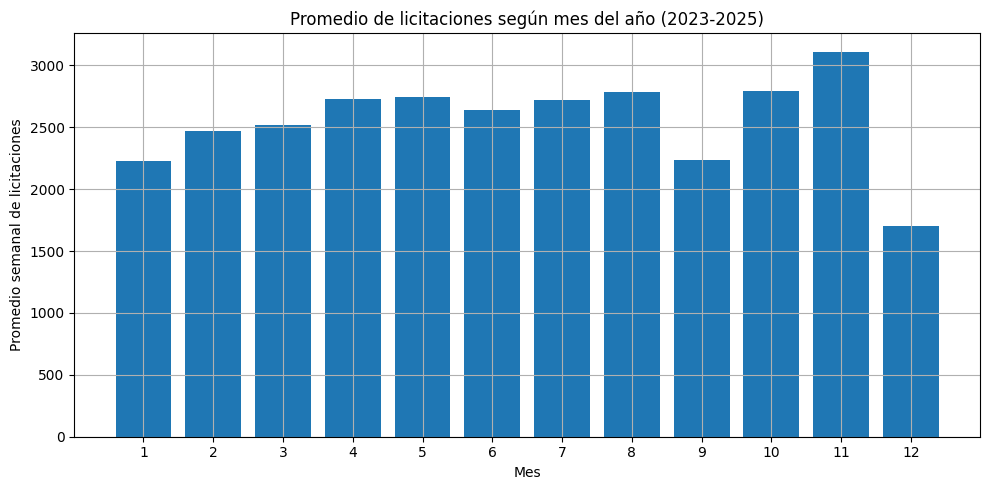

In [19]:
# Serie semanal
serie_semanal = lic_total.copy()

# Serie mensual
serie_mensual = serie_semanal.resample("MS").mean()

# Media movil
media_movil = serie_semanal.rolling(window=4).mean()

# Grafico serie semanal junto a media movil
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(serie_semanal.index, serie_semanal, label="Serie semanal")
ax.plot(media_movil.index, media_movil, color="tab:green", label="Media móvil 4 semanas")
ax.set_title("Licitaciones semanales en Chile (2023-2025) - Media móvil 4 semanas")
ax.set_xlabel("Fecha")
ax.set_ylabel("Cantidad de licitaciones")
ax.legend()
plt.tight_layout()
plt.show()
plt.close(fig)

# Grafico serie mensual
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(serie_mensual.index, serie_mensual, marker="o")
ax.set_title("Promedio semanal de licitaciones por mes (2023-2025)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Promedio de licitaciones semanales")
plt.tight_layout()
plt.show()
plt.close(fig)

# Promedio por mes del año
promedio_mensual = serie_semanal.groupby(serie_semanal.index.month).mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(promedio_mensual.index, promedio_mensual)
ax.set_title("Promedio de licitaciones según mes del año (2023-2025)")
ax.set_xlabel("Mes")
ax.set_ylabel("Promedio semanal de licitaciones")
ax.set_xticks(range(1, 13))
plt.tight_layout()
plt.show()
plt.close(fig)

## Descomposición

En este caso utilizaremos la serie mensual para poder visualizar los patrones generales.

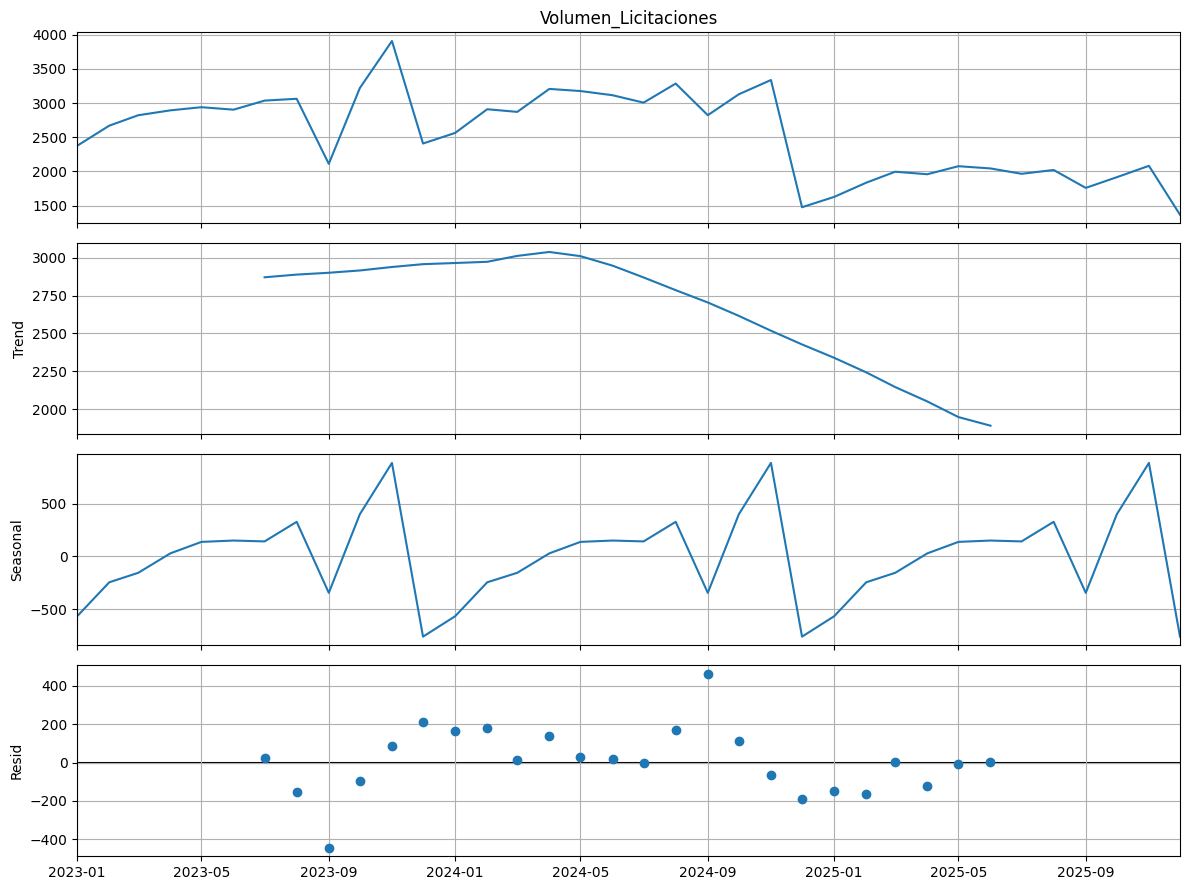

Tendencia (primeras filas, con NaN por la media móvil centrada):
Semana
2023-01-01            NaN
2023-02-01            NaN
2023-03-01            NaN
2023-04-01            NaN
2023-05-01            NaN
2023-06-01            NaN
2023-07-01    2869.920833
2023-08-01    2887.745833
Freq: MS, Name: trend, dtype: float64

Estacionalidad (primeros 12 valores, un ciclo completo):
Semana
2023-01-01   -565.636979
2023-02-01   -244.536979
2023-03-01   -154.870313
2023-04-01     28.883854
2023-05-01    137.282812
2023-06-01    150.125521
2023-07-01    141.818229
2023-08-01    327.057813
2023-09-01   -344.447396
2023-10-01    398.835937
2023-11-01    883.760937
2023-12-01   -758.273437
Freq: MS, Name: seasonal, dtype: float64


In [27]:
# SEASONAL DECOMPOSE
resultado_sd = seasonal_decompose(serie_mensual, model="additive", period=12)
fig = resultado_sd.plot()
fig.set_size_inches(12, 9)
plt.tight_layout()
plt.show()
print("Tendencia (primeras filas, con NaN por la media móvil centrada):")
print(resultado_sd.trend.head(8))
print()
print("Estacionalidad (primeros 12 valores, un ciclo completo):")
print(resultado_sd.seasonal.head(12))

### Comentarios:
Al realizar la descomposición, podemos observar una tendencia creciente durante 2023 y principios de 2024, seguida de una disminución durante 2025.

En cuanto a la estacionalidad, se observan patrones que se repiten cada año, destacando noviembre como uno de los meses con mayor cantidad de licitaciones, mientras que diciembre y enero presentan una menor actividad.

Finalmente, los residuales muestran algunas variaciones importantes, especialmente durante 2023 y 2024, lo que indica que existen comportamientos que no son explicados completamente por la tendencia y estacionalidad.

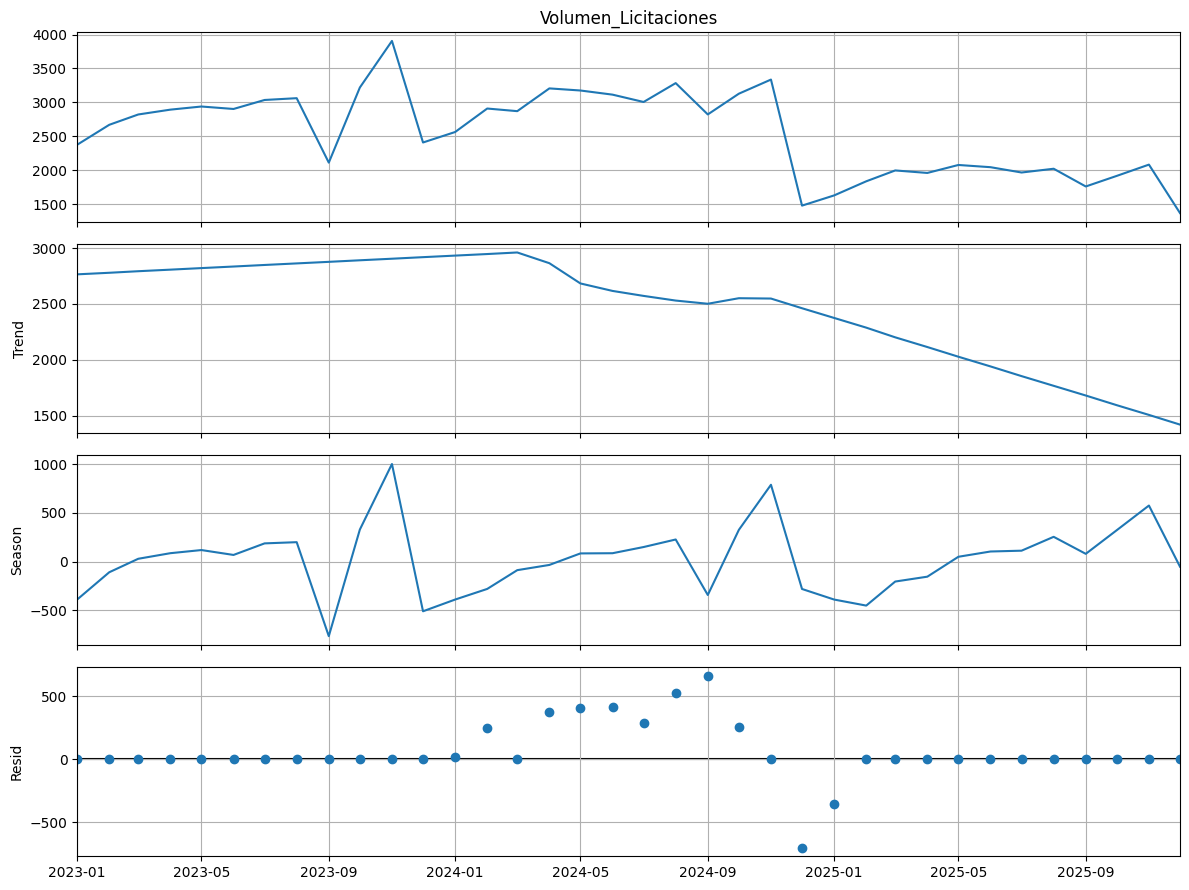

Tendencia (primeras filas, con NaN por la media móvil centrada):
Semana
2023-01-01    2765.170357
2023-02-01    2779.143706
2023-03-01    2793.117055
2023-04-01    2807.090404
2023-05-01    2821.063753
2023-06-01    2835.037102
2023-07-01    2849.010451
2023-08-01    2862.983800
Freq: MS, Name: trend, dtype: float64

Estacionalidad (primeros 12 valores, un ciclo completo):
Semana
2023-01-01    -389.770357
2023-02-01    -109.643706
2023-03-01      28.632945
2023-04-01      85.909596
2023-05-01     118.136247
2023-06-01      67.962898
2023-07-01     186.589549
2023-08-01     199.016200
2023-09-01    -765.207149
2023-10-01     328.269502
2023-11-01    1001.096153
2023-12-01    -510.127196
Freq: MS, Name: season, dtype: float64


In [26]:
# STL
resultado_stl = STL(serie_mensual, period=12, robust=True).fit()
fig = resultado_stl.plot()
fig.set_size_inches(12, 9)
plt.tight_layout()
plt.show()

print("Tendencia (primeras filas, con NaN por la media móvil centrada):")
print(resultado_stl.trend.head(8))
print()
print("Estacionalidad (primeros 12 valores, un ciclo completo):")
print(resultado_stl.seasonal.head(12))


### Comentarios:

Al utilizar STL, podemos observar una tendencia similar a la obtenida anteriormente, con un crecimiento durante 2023 y principios de 2024, seguido de una disminución importante durante 2025.

Respecto a la estacionalidad, se identifican patrones similares, con una mayor actividad relativa en noviembre y una menor actividad en diciembre y septiembre.

Por otro lado, los residuales presentan valores cercanos a cero durante gran parte del período, aunque se observan algunas variaciones importantes durante 2024 y principios de 2025.


## Estacionariedad y autocorrelación
Alicamos test ADF a la serie mensual. Graficos ACF y PACF de la serie transforamda.

--- ADF: Serie mensual ---
Estadístico: -0.7186  |  p-value: 0.8419
Conclusión: NO estacionaria 

--- ADF: Serie log + diff(1) ---
Estadístico: -6.8791  |  p-value: 0.0000
Conclusión: ESTACIONARIA 



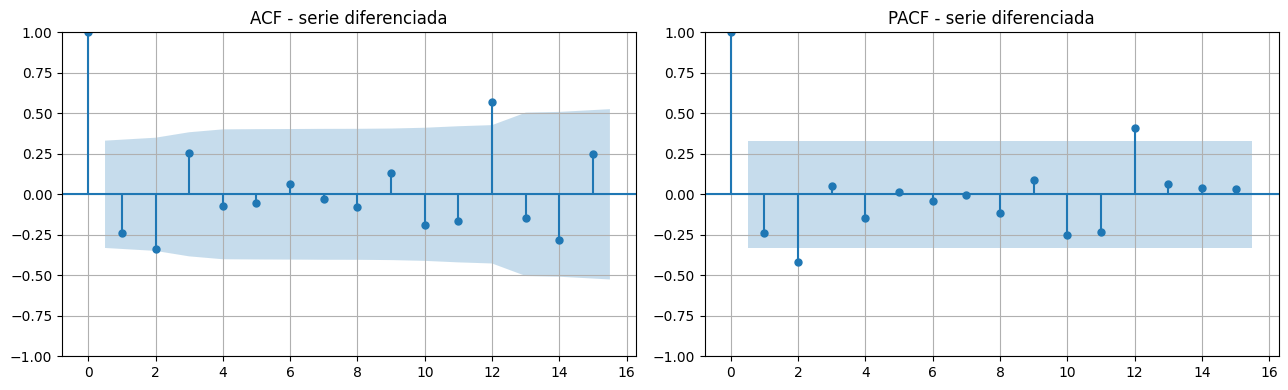

In [37]:
# Función test ADF
def test_adf(x, nombre="serie"):
    resultado = adfuller(x.dropna())
    print(f"--- ADF: {nombre} ---")
    print(f"Estadístico: {resultado[0]:.4f}  |  p-value: {resultado[1]:.4f}")
    print("Conclusión:", "ESTACIONARIA" if resultado[1] < 0.05 else "NO estacionaria", "\n")

test_adf(serie_mensual, "Serie mensual")

# Transformación logarítmica
log_serie = np.log(serie_mensual)

# Diferenciación de orden 1
diff_serie = log_serie.diff().dropna()

test_adf(diff_serie, "Serie log + diff(1)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(diff_serie, lags=15, ax=axes[0])
axes[0].set_title("ACF - serie diferenciada")
plot_pacf(diff_serie, lags=15, ax=axes[1], method="ywm")
axes[1].set_title("PACF - serie diferenciada")
plt.tight_layout()
plt.show()

Alicamos test ADF a la serie semanal. Separamos 145 semanas de train y 12 de test (los que usaremos para los modelos luego).
Graficos ACF y PACF de la serie transforamda.

Entrenamiento: 145
Prueba: 12
--- ADF: Serie semanal ---
Estadístico: -3.4773  |  p-value: 0.0086
Conclusión: ESTACIONARIA 



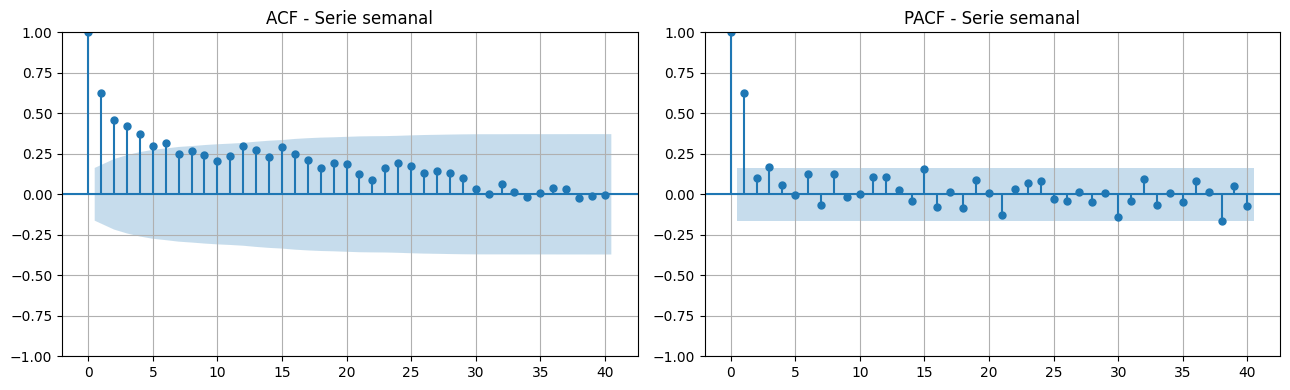

In [43]:
# Separacion entrenamiento y prueba
train = serie_semanal.iloc[:-12]
test = serie_semanal.iloc[-12:]

print("Entrenamiento:", len(train))
print("Prueba:", len(test))

def test_adf(x, nombre="serie"):
    resultado = adfuller(x.dropna())
    print(f"--- ADF: {nombre} ---")
    print(f"Estadístico: {resultado[0]:.4f}  |  p-value: {resultado[1]:.4f}")
    print("Conclusión:", "ESTACIONARIA" if resultado[1] < 0.05 else "NO estacionaria", "\n")

test_adf(train, "Serie semanal")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(train, lags=40, ax=axes[0])
axes[0].set_title("ACF - Serie semanal")
plot_pacf(train, lags=40, ax=axes[1], method="ywm")
axes[1].set_title("PACF - Serie semanal")
plt.tight_layout()
plt.show()

### Comentarios:
Ya que la serie es estacionaria, no es necesario realizar diferenciación.

## Modelos de Forecasting

        Modelo         AIC        MAE       RMSE
ARIMA(2, 0, 1) 2254.920251 455.992587 648.780530
ARIMA(1, 0, 1) 2257.095293 702.910706 866.613782
ARIMA(2, 0, 0) 2258.570146 767.617064 911.838350
ARIMA(1, 0, 0) 2257.924371 796.174601 929.739720

Mejor modelo: ARIMA(2,0,1)


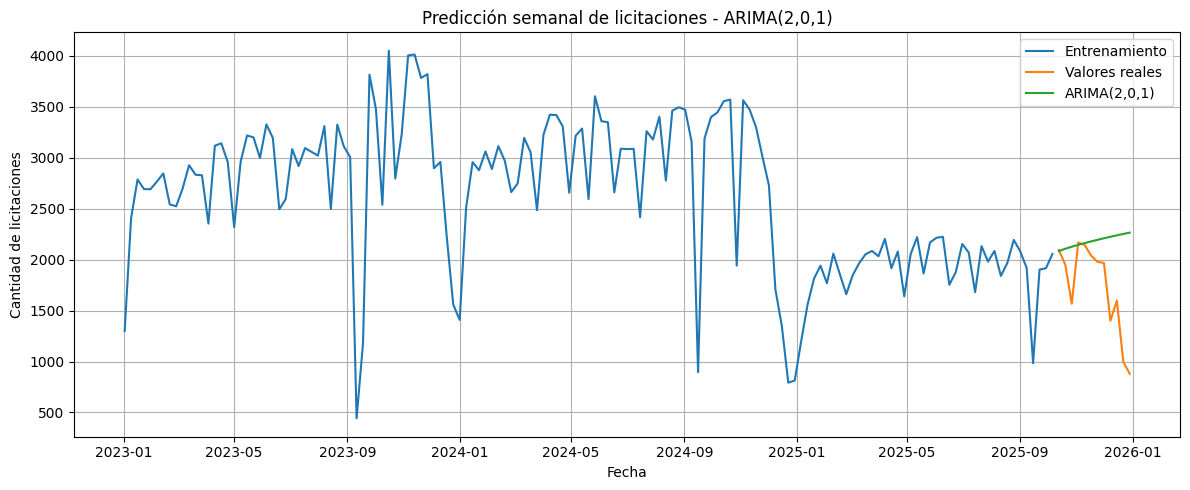

In [80]:
# ARIMA

modelos = [
    (1, 0, 0),
    (2, 0, 0),
    (1, 0, 1),
    (2, 0, 1)
]

resultados = []

# Entrenamiento y evaluacion
for orden in modelos:
    modelo = ARIMA(train, order=orden).fit()
    predicciones = modelo.forecast(steps=len(test))

    mae = mean_absolute_error(test, predicciones)
    rmse = np.sqrt(mean_squared_error(test, predicciones))

    resultados.append({
        "Modelo": f"ARIMA{orden}",
        "AIC": modelo.aic,
        "MAE": mae,
        "RMSE": rmse
    })

# Comparacion de resultados
df_resultados = pd.DataFrame(resultados)
df_resultados = df_resultados.sort_values("RMSE")

print(df_resultados.to_string(index=False))

# Mejor modelo segun RMSE
modelo_arima = ARIMA(train, order=(2, 0, 1)).fit()
mejor_prediccion = modelo_arima.forecast(steps=len(test))

print("")
print("Mejor modelo: ARIMA(2,0,1)")

# Grafico de predicciones
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(train.index, train, label="Entrenamiento")
ax.plot(test.index, test, label="Valores reales", color="tab:orange")
ax.plot(mejor_prediccion.index, mejor_prediccion, label="ARIMA(2,0,1)", color="tab:green")

ax.set_title("Predicción semanal de licitaciones - ARIMA(2,0,1)")
ax.set_xlabel("Fecha")
ax.set_ylabel("Cantidad de licitaciones")
ax.legend()

plt.tight_layout()
plt.show()

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=0.52 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=2267.937, Time=0.02 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=2260.714, Time=0.05 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=2250.757, Time=0.10 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=2265.948, Time=0.02 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=2240.999, Time=0.24 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=2242.938, Time=0.34 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=2242.898, Time=0.40 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=2242.491, Time=0.21 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=2252.172, Time=0.05 sec
 ARIMA(1,1,1)(0,0,0)[0]             : AIC=2239.207, Time=0.14 sec
 ARIMA(0,1,1)(0,0,0)[0]             : AIC=2248.755, Time=0.07 sec
 ARIMA(1,1,0)(0,0,0)[0]             : AIC=2258.708, Time=0.03 sec
 ARIMA(2,1,1)(0,0,0)[0]             : AIC=2241.128, Time=0.17 sec
 ARIMA(1,1,2)(0,0,0)[0]             : 

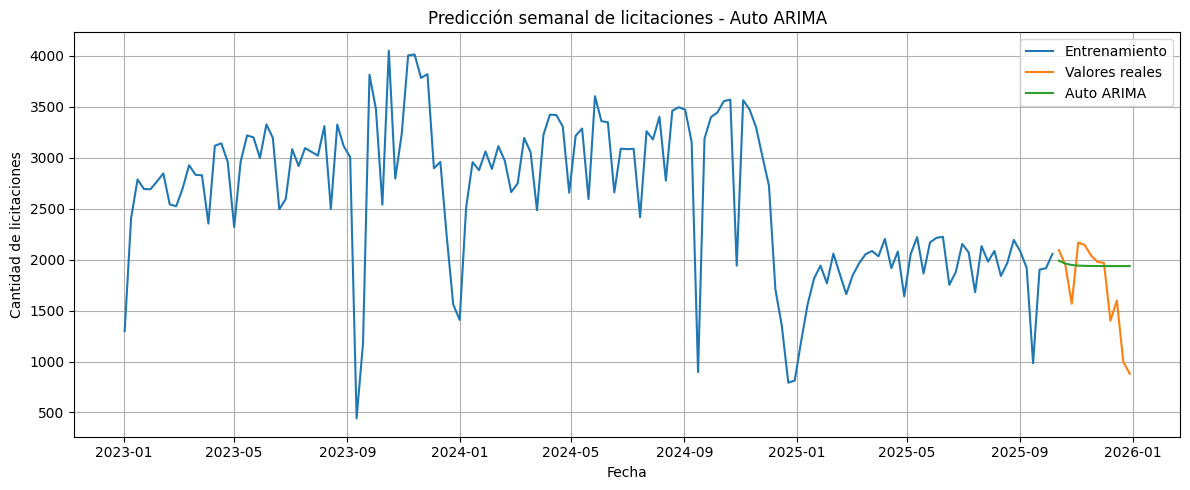

In [63]:
# Auto_Arima

modelo_auto = pm.auto_arima(
    train,
    seasonal=False,
    stepwise=True,
    suppress_warnings=True,
    trace=True
)

print(modelo_auto.summary())

# Predicciones Auto ARIMA
pred_auto = pd.Series(
    modelo_auto.predict(n_periods=len(test)),
    index=test.index
)

# Evaluacion
mae_auto = mean_absolute_error(test, pred_auto)
rmse_auto = np.sqrt(mean_squared_error(test, pred_auto))

print("Modelo seleccionado:", modelo_auto.order)
print("AIC:", round(modelo_auto.aic(), 2))
print("MAE:", round(mae_auto, 2))
print("RMSE:", round(rmse_auto, 2))

# Grafico
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(train.index, train, label="Entrenamiento")
ax.plot(test.index, test, label="Valores reales", color="tab:orange")
ax.plot(pred_auto.index, pred_auto, label="Auto ARIMA", color="tab:green")

ax.set_title("Predicción semanal de licitaciones - Auto ARIMA")
ax.set_xlabel("Fecha")
ax.set_ylabel("Cantidad de licitaciones")
ax.legend()

plt.tight_layout()
plt.show()

                      Modelo         AIC        MAE       RMSE
SARIMA(2, 0, 1)(1, 0, 0, 52) 2225.031257 242.915532 315.280344
SARIMA(1, 0, 0)(1, 0, 0, 52) 2261.189950 269.484340 320.513515
SARIMA(1, 0, 1)(1, 0, 0, 52) 2224.475437 290.410065 377.948046

Mejor modelo: SARIMA(1,0,0)(1,0,0,52)


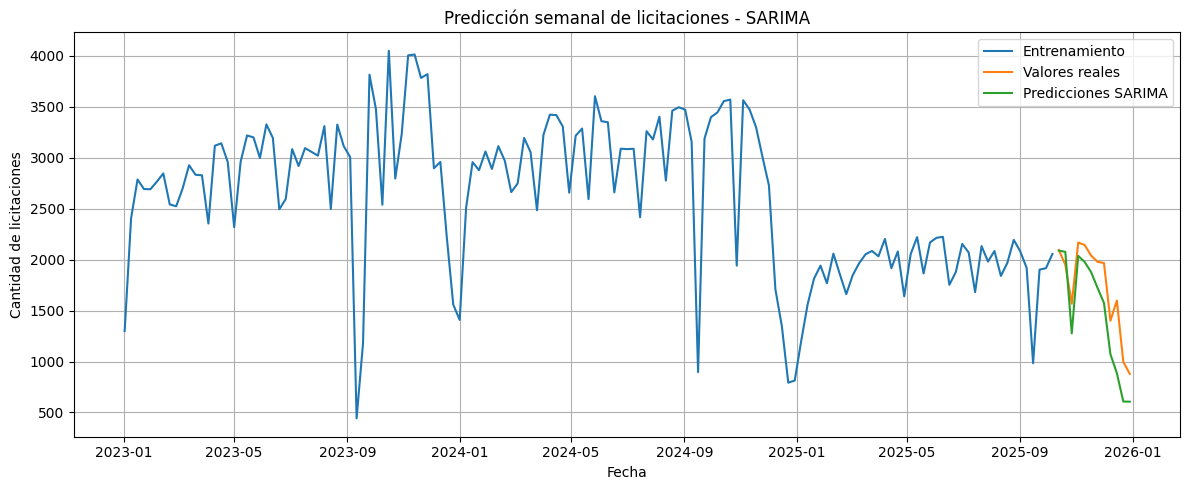

In [79]:
# SARIMA

modelos_sarima = [
    ((1, 0, 0), (1, 0, 0, 52)),
    ((1, 0, 1), (1, 0, 0, 52)),
    ((2, 0, 1), (1, 0, 0, 52))
]

resultados_sarima = []

# Entrenamiento y evaluacion
for orden, estacional in modelos_sarima:
    modelo = SARIMAX(
        train,
        order=orden,
        seasonal_order=estacional
    ).fit()

    predicciones = modelo.forecast(steps=len(test))
    mae = mean_absolute_error(test, predicciones)
    rmse = np.sqrt(mean_squared_error(test, predicciones))

    resultados_sarima.append({
        "Modelo": f"SARIMA{orden}{estacional}",
        "AIC": modelo.aic,
        "MAE": mae,
        "RMSE": rmse
    })

# Comparacion de resultados
df_sarima = pd.DataFrame(resultados_sarima)
df_sarima = df_sarima.sort_values("RMSE")
print(df_sarima.to_string(index=False))

# Mejor modelo segun RMSE
modelo_sarima = SARIMAX(train,order=(1, 0, 0), seasonal_order=(1, 0, 0, 52)).fit()
mejor_prediccion = modelo_sarima.forecast(steps=len(test))

print("")
print("Mejor modelo: SARIMA(1,0,0)(1,0,0,52)")

# Grafico de predicciones
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(train.index, train, label="Entrenamiento")
ax.plot(test.index, test, label="Valores reales", color="tab:orange")
ax.plot(mejor_prediccion.index, mejor_prediccion,
        label="Predicciones SARIMA", color="tab:green")

ax.set_title("Predicción semanal de licitaciones - SARIMA")
ax.set_xlabel("Fecha")
ax.set_ylabel("Cantidad de licitaciones")
ax.legend()

plt.tight_layout()
plt.show()

MAE: 423.66
RMSE: 513.88


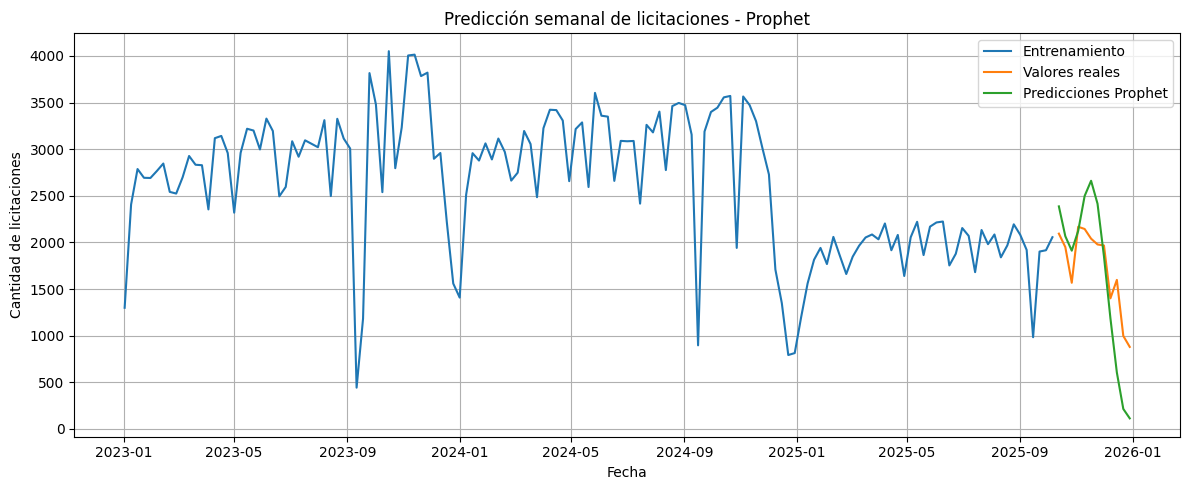

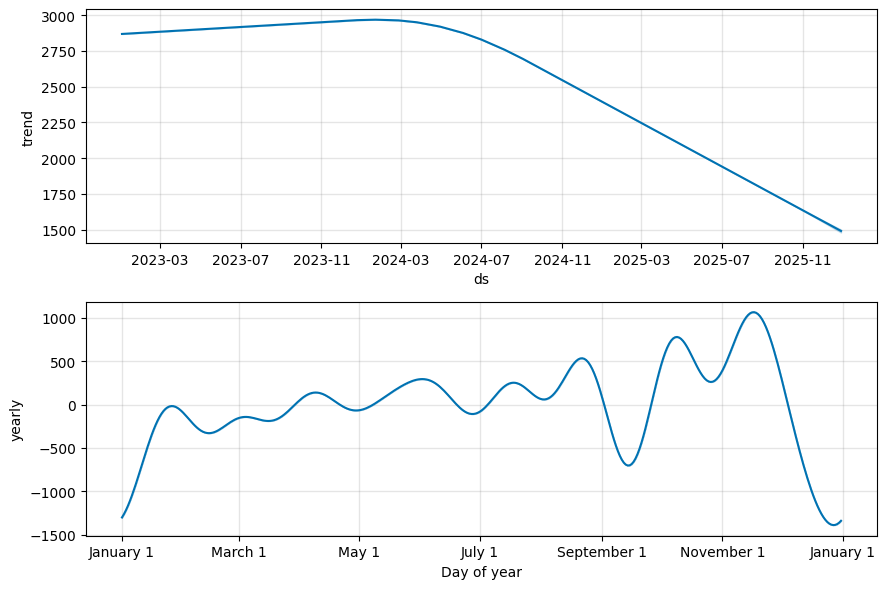

In [76]:
# Prophet

# Preparacion de datos
train_prophet = train.reset_index()
train_prophet.columns = ["ds", "y"]

test_prophet = test.reset_index()
test_prophet.columns = ["ds", "y"]

# Entrenamiento
modelo_prophet = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
modelo_prophet.fit(train_prophet)

# Predicciones
futuro = modelo_prophet.make_future_dataframe(periods=len(test), freq="W-MON")
predicciones = modelo_prophet.predict(futuro)

pred_prophet = predicciones.set_index("ds").loc[test.index, "yhat"]

# Evaluacion
mae = mean_absolute_error(test, pred_prophet)
rmse = np.sqrt(mean_squared_error(test, pred_prophet))

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

# Grafico de predicciones
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(train.index, train, label="Entrenamiento")
ax.plot(test.index, test, label="Valores reales", color="tab:orange")
ax.plot(pred_prophet.index, pred_prophet, label="Predicciones Prophet", color="tab:green")

ax.set_title("Predicción semanal de licitaciones - Prophet")
ax.set_xlabel("Fecha")
ax.set_ylabel("Cantidad de licitaciones")
ax.legend()

plt.tight_layout()
plt.show()

fig = modelo_prophet.plot_components(predicciones)
plt.show()

### Comparación

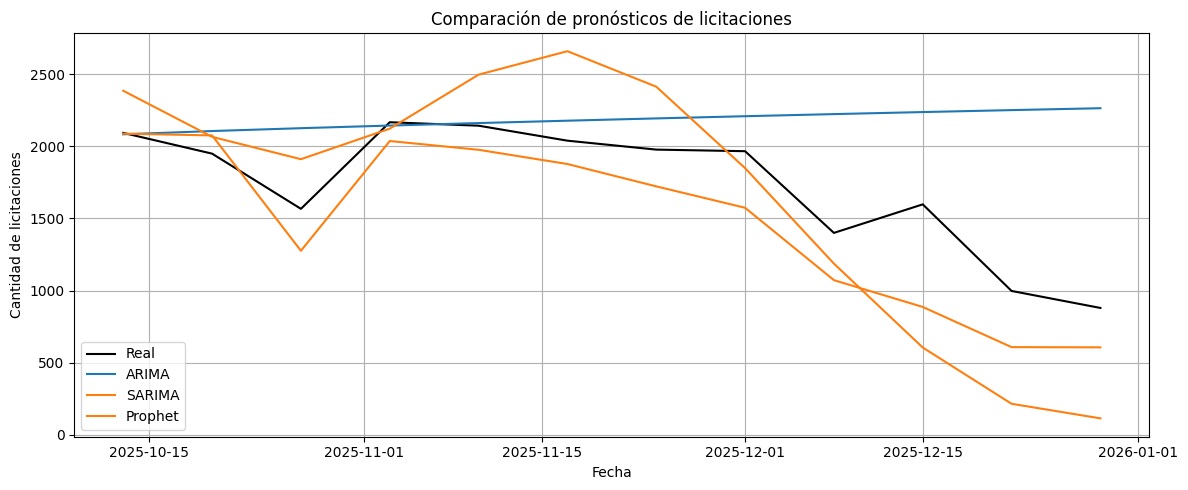

,MAE,RMSE,MAPE
ARIMA,455.99,648.78,38.23
SARIMA,269.48,320.51,18.18
Prophet,423.66,513.88,30.18


In [82]:
# Grafico comparativo
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(test.index, test.values, label="Real", color="black")
ax.plot(test.index, pred_arima, label="ARIMA")
ax.plot(test.index, pred_sarima, label="SARIMA")
ax.plot(test.index, pred_prophet, label="Prophet", color="tab:orange")

ax.set_title("Comparación de pronósticos de licitaciones")
ax.set_xlabel("Fecha")
ax.set_ylabel("Cantidad de licitaciones")
ax.legend()

plt.tight_layout()
plt.show()

# Comparacion de metricas
datos = [[mean_absolute_error(test, pred_arima), np.sqrt(mean_squared_error(test, pred_arima)), mean_absolute_percentage_error(test, pred_arima)*100],
        [mean_absolute_error(test, pred_sarima), np.sqrt(mean_squared_error(test, pred_sarima)), mean_absolute_percentage_error(test, pred_sarima)*100],
        [mean_absolute_error(test, pred_prophet), np.sqrt(mean_squared_error(test, pred_prophet)), mean_absolute_percentage_error(test, pred_prophet)*100]]

df_comparacion = pd.DataFrame(
    datos,
    columns=["MAE", "RMSE", "MAPE"],
    index=["ARIMA", "SARIMA", "Prophet"]
)

df_comparacion.round(2)